# Limpeza e Preparação dos dados

Normalmente não há problema nenhum com os dados encontrados nos exemplos e nos tutoriais, mas os dados do mundo real raramente são "limpos" e homogéneo.
Muitos _datasets_ encontrados no mundo real contêm dados em falta, e para complicar ainda mais, fontes diferentes podem utilizar formas diferentes de assinalar dados em falta.
Podem também faltar casas decimais, ter zeros a mais, existir erros tipográficos, e um sem número de outros problemas que devem ser resolvidos antes de se poder fazer a análise dos dados.

O que faz com que um _datasets_ não esteja "limpo"? Alguns dos factores que indicam que os dados necessitam de alguma preparação antes de se poder utilizar são os seguintes:

* **Dados incompletos**: alguns atributos têm valores em falta, alguns atributos de interesse não estão presentes, os atributos contém apenas dados agregados, etc.
* **Dados com ruído**: existem erros ou _outliers_ dos dados.
* **Dados inconsistentes**: existem discrepâncias nos dados ou nos nomes. Por exemplo, na coluna "Nome" existirem outros valores que não são apenas letras.

Tal como existem muitas formas dos dados estarem "sujos" (_dirty_), também existem muitas maneira diferentes de os "limpar". De forma geral, existem 3 opções para "tratar" o problema de dados "sujos": Removê-los, corrigi-los ou ignorá-los. Se existe um registo "errado" num milhão de outros registos, talvez de possa simplesmente ignorar ou remover esse registo, mas se grande parte dos registos contém erros, a abordagem deverá ser diferente.

> **<p style='font-size:30pt; text-align:center'>A limpeza e preparação dos dados pode levar 80% do tempo da análise de dados</p>**

No contexto da análise de dados, uma parte muito significativa do tempo é gasto nas tarefas de limpeza e preparação dos dos dados, sendo reportado com frequência que estas tarefas demoram 80% ou mais do tempo do analista. Muitas vezes a forma como os dados estão guardados não é a forma ideal para uma determinada tarefa.

## Tratar os dados em falta

Não existem uma resposta única, simples e boa sobre como tratar dados em falta, é necessário encontrar uma estratégia adequada para cada caso, como seja ignorar esses registos ou utilizar um valor constante para substituir os valores em falta, entre outros.

### O que são dados em falta (_missing values_)

O pandas faz com que trabalhar com dados em falta seja tão fácil quanto possível, as funções de estatística descritiva dos objectos do pandas excluem os dados em falta por defeito.

A forma que o pandas utiliza para representar dados em falta não é perfeita, mas é suficiente para a sua utilização em problemas do mundo real.

Dependendo do tipo de dados, assim o pandas utiliza uma simbologia diferente para representar valores em falta:

* `NaN` (outra forma de representar `numpy.nan`) (_Not a Number_) para tipos de dados no Numpy. Tem a desvantagem que o tipo de dados dados será sempre alterado para `float64` ou `object`
* `NaT` (_Not a Time_) para dados do tipo data (`numpy.datetime64` e `numpy.timedelta64`)
* `NA` (_Not Available_) para os tipos `string`, `Int64` e `Float64` (ou outros tamanhos). Este tipos vão manter os tipos de dados originais.

Esta representação chama-se um valor sentinela, e quanto está presente significa que o valor em causa está ausente ou é _null_.

In [1]:
import pandas as pd
import numpy as np

pd.options.display.max_columns = 999

In [2]:
f = pd.Series([1.2, -4.2, 5, np.nan, 2], name='float')
f

0    1.2
1   -4.2
2    5.0
3    NaN
4    2.0
Name: float, dtype: float64

Repare-se que o pandas cria a `Series` de acordo com os dados que consegue identificar. Caso os dados sejam apenas valores inteiros irá criar uma `Series` do tipo `int64`, mas, como já foi dito anteriormente, basta que exista um valor nulo para já não ser desse tipo.

In [3]:
pd.Series([1, 5, 3])

0    1
1    5
2    3
dtype: int64

In [4]:
pd.Series([1, 5, 3, np.nan])

0    1.0
1    5.0
2    3.0
3    NaN
dtype: float64

In [5]:
t = pd.Series(['2024-01-01', pd.NaT, '2024-12-25', np.nan, '2026-09-23'],
              name='date')
t = pd.to_datetime(t)
t

0   2024-01-01
1          NaT
2   2024-12-25
3          NaT
4   2026-09-23
Name: date, dtype: datetime64[us]

In [6]:
st = pd.Series(['ola',  pd.NA, '', np.nan, None, pd.NaT],
               dtype='string', name='string')
st

0     ola
1    <NA>
2        
3    <NA>
4    <NA>
5    <NA>
Name: string, dtype: string

Como se vê no exemplo acima, o pandas reconhece também o valor `None` como valor em falta, mas repare-se que uma **string vazia não é considerado um valor em falta**.

In [7]:
df = pd.concat([f, t, st], axis=1)

In [8]:
df

,float,date,string
0,1.2,2024-01-01,ola
1,-4.2,NaT,<NA>
2,5.0,2024-12-25,
3,NaN,NaT,<NA>
4,2.0,2026-09-23,<NA>
5,NaN,NaT,<NA>


O método `isna` devolve um array booleano, com o valor `True` caso seja um valor em falta:

In [9]:
df.isna()

,float,date,string
0,False,False,False
1,False,True,True
2,False,False,False
3,True,True,True
4,False,False,True
5,True,True,True


Existe também o método `notna`, que devolva também um array booleano, mas agora com o valor `True` caso não seja um valor em falta:

In [10]:
df.notna()

,float,date,string
0,True,True,True
1,True,False,False
2,True,True,True
3,False,False,False
4,True,True,False
5,False,False,False


Estes métodos permitem identificar valores em falta, independentemente do tipo de dados.

Podemos obter a quantidade de valores em falta em cada coluna somando o resultado de `df.isna()`:

In [11]:
df.isna().sum()

float     2
date      3
string    4
dtype: int64

E a percentagem dos valores em falta em cada coluna:

In [12]:
df.isna().mean() * 100

float     33.333333
date      50.000000
string    66.666667
dtype: float64

> **NOTA:**
>
> A não ser que seja explicitamente indicado, todas as funções de transformação utilizadas não alteram o objeto base, mas devolvem uma cópia desse objeto com essas transformações. Caso se pretenda alterar o próprio objecto deve ser passado o parâmetro `inplace=True`.

### Filtrando os dados em falta

Ok, identificamos quais os valores em falta, e agora fazemos o quê?

Como vimos acima, uma das hipóteses é remover esses elementos dos nossos dados, e trabalhamos apenas com os valores não vazios.

Isso pode ser feito de forma indireta, utilizando o métodos `isna` ou `notna`, ou utilizando o método direto `dropna`.

No caso de uma `Series`, remove os valores em falta vai devolver a `Series` apenas com os valores existentes:

In [13]:
data = pd.Series([1.3, np.nan, 3.4, np.nan, 2.4])
data

0    1.3
1    NaN
2    3.4
3    NaN
4    2.4
dtype: float64

In [14]:
data[data.notna()]

0    1.3
2    3.4
4    2.4
dtype: float64

O resultado é igual a utilizar o método `dropna`:

In [15]:
data.dropna()

0    1.3
2    3.4
4    2.4
dtype: float64

No caso de um `DataFrame`, existem diversas formas de remover dados em falta: Pode-se remover linhas ou colunas caso todos os elementos estejam em falta, ou desde que exista um elemento em falta. Por defeito, o método `dropna` remove as linhas que contenham pelo menos um valor em falta:

In [16]:
df

,float,date,string
0,1.2,2024-01-01,ola
1,-4.2,NaT,<NA>
2,5.0,2024-12-25,
3,NaN,NaT,<NA>
4,2.0,2026-09-23,<NA>
5,NaN,NaT,<NA>


In [17]:
df.dropna()

,float,date,string
0,1.2,2024-01-01,ola
2,5.0,2024-12-25,


Caso se queira remover as colunas, pode-se passar o parâmetro `axis=1` (ou `axis='columns'`).

Mas desta forma também serão removidos alguns dados válidos. Podemos querer apenas remover linhas ou colunas onde _todos_ os dados estejam em falta, ou onde a maioria dos dados esteja em falta. Isso pode ser feito utilizando os parâmetros `how` e `thresh`, que permite um melhor ajuste sobre os dados a apagar.

O valor por defeito é `how=any`, que faz com que sejam removidas as linhas ou colunas se existir pelo menos um valor em falta. Pode-se indicar `how=all`, que faz com que apenas sejam removidas as linhas ou colunas se todos os elementos estiveram em falta:

In [18]:
df['vazia'] = None
df

,float,date,string,vazia
0,1.2,2024-01-01,ola,None
1,-4.2,NaT,<NA>,None
2,5.0,2024-12-25,,None
3,NaN,NaT,<NA>,None
4,2.0,2026-09-23,<NA>,None
5,NaN,NaT,<NA>,None


In [19]:
df.dropna(axis=0, how='all')

,float,date,string,vazia
0,1.2,2024-01-01,ola,None
1,-4.2,NaT,<NA>,None
2,5.0,2024-12-25,,None
4,2.0,2026-09-23,<NA>,None


O parâmetro `thresh` (_threshold_) permite indicar a quantidade mínima de valores não vazios que devem existir em cada linha/coluna, caso contrário será removida.

In [20]:
df.dropna(thresh=2)

,float,date,string,vazia
0,1.2,2024-01-01,ola,None
2,5.0,2024-12-25,,None
4,2.0,2026-09-23,<NA>,None


> **NOTA:**
>
> Não se pode utilizar o parâmetro `how` e `thresh` em simultâneo.

Também se pode indicar quais as colunas a considerar para verificar os valores em falta com o parametro `subset`:

In [21]:
df.dropna(subset=['float'])

,float,date,string,vazia
0,1.2,2024-01-01,ola,None
1,-4.2,NaT,<NA>,None
2,5.0,2024-12-25,,None
4,2.0,2026-09-23,<NA>,None


### Preenchendo dados em falta

Em vez de remover os elementos em falta (e remover dados válidos em simultâneo), outra hipóteses é, de alguma forma, preencher os elementos em falta. Isso pode ser feito com a método `fillna`. Chamar esse método passando o valor de uma constante fará com que todos os elementos em falta sejam preenchidos por esse valor:

In [22]:
f

0    1.2
1   -4.2
2    5.0
3    NaN
4    2.0
Name: float, dtype: float64

In [23]:
f.fillna(0)

0    1.2
1   -4.2
2    5.0
3    0.0
4    2.0
Name: float, dtype: float64

No caso de um `DataFrame`, dependendo do tipo das colunas, e na homogeneidade dessas colunas entre si, pode ser utilizado um único valor para todos os elementos em falta, ou ser necessário indicar um dicionário, com o elemento a preencher em cada coluna.

Por exemplo, o `DataFrame` que estamos a exemplificar tem colunas com dados `float64`, `datatime64`, `string` e `object`.

In [24]:
df.dtypes

float            float64
date      datetime64[us]
string            string
vazia             object
dtype: object

Aplicar `fillna` com o mesmo valor para todas as colunas quando os tipo de dados não são os mesmos, normalmente não será grande ideia, pois o mais certo é ou provocar um erro, pois os diferentes tipos não são compatíveis, ou converter os tipos de dados, o que pode trazer outros problemas no futuro.

In [25]:
try:
    df.fillna(0)
except TypeError as e:
    print(f'TypeError: {e}')

O que se pode fazer é fornecer um dicionário com o valor a utilizar para cada coluna, sendo a chave o nome das colunas. As colunas que não forem indicadas não serão alteradas.

In [26]:
vazios = {'float': 0, 'date': '2000-01-01', 'string': ''}
df.fillna(vazios)

,float,date,string,vazia
0,1.2,2024-01-01,ola,None
1,-4.2,2000-01-01,,None
2,5.0,2024-12-25,,None
3,0.0,2000-01-01,,None
4,2.0,2026-09-23,,None
5,0.0,2000-01-01,,None


Dependo do tipo de dados, em vez de se indicar um valor, pode-se fazer uma imputação simples, utilizando funções estatísticas como a média ou a mediana. Considere os dados no ficheiro `exemplos\matriz1.csv`:

In [27]:
!type exemplos\matriz1.csv

-0.9446,0.2247,-0.6318
---,1.6778,---
---,---,0.6526
0.8456,---,---
---,---,---
0.4649,-0.2548,0.5683
-0.6027,---,1.0573


Podemos ver que existem valores vazios (representados por `---`) e que não existe nenhum cabeçalho para as colunas. Vamos ler esse ficheiro para um `DataFrame`:

In [28]:
df = pd.read_csv(r'exemplos\matriz1.csv', header=None, na_values='---')
df

,0,1,2
0,-0.9446,0.2247,-0.6318
1,NaN,1.6778,NaN
2,NaN,NaN,0.6526
3,0.8456,NaN,NaN
4,NaN,NaN,NaN
5,0.4649,-0.2548,0.5683
6,-0.6027,NaN,1.0573


E vamos preencher esses valores em falta utilizando a média dos valores de cada coluna:

In [29]:
df.mean()

0   -0.059200
1    0.549233
2    0.411600
dtype: float64

In [30]:
df.fillna(df.mean())

,0,1,2
0,-0.9446,0.224700,-0.6318
1,-0.0592,1.677800,0.4116
2,-0.0592,0.549233,0.6526
3,0.8456,0.549233,0.4116
4,-0.0592,0.549233,0.4116
5,0.4649,-0.254800,0.5683
6,-0.6027,0.549233,1.0573


In [31]:
df.mean()

0   -0.059200
1    0.549233
2    0.411600
dtype: float64

Por vezes, o mais indicado será não utilizar sempre o mesmo valor, mas utilizar o último valor conhecido. Isso pode ser feito utilizando os métodos `ffill` (_forward fill_) e `bfill` (_backward fill_), que preenchem os valores em falta "repetindo" o último valor conhecido acima (`ffill`) ou abaixo (`bfill`).

In [32]:
df

,0,1,2
0,-0.9446,0.2247,-0.6318
1,NaN,1.6778,NaN
2,NaN,NaN,0.6526
3,0.8456,NaN,NaN
4,NaN,NaN,NaN
5,0.4649,-0.2548,0.5683
6,-0.6027,NaN,1.0573


In [33]:
df.ffill()

,0,1,2
0,-0.9446,0.2247,-0.6318
1,-0.9446,1.6778,-0.6318
2,-0.9446,1.6778,0.6526
3,0.8456,1.6778,0.6526
4,0.8456,1.6778,0.6526
5,0.4649,-0.2548,0.5683
6,-0.6027,-0.2548,1.0573


In [34]:
df.bfill()

,0,1,2
0,-0.9446,0.2247,-0.6318
1,0.8456,1.6778,0.6526
2,0.8456,-0.2548,0.6526
3,0.8456,-0.2548,0.5683
4,0.4649,-0.2548,0.5683
5,0.4649,-0.2548,0.5683
6,-0.6027,NaN,1.0573


Note-se que, caso o primeiro valor a substituir esteja em falta, continuará em falta, pois ainda não existe valor válido para utilizar.

Também se pode utilizar o parâmetro `limit`, indicando o máximo de valores consecutivos que serão preenchidos:

In [35]:
df.bfill(limit=1)

,0,1,2
0,-0.9446,0.2247,-0.6318
1,NaN,1.6778,0.6526
2,0.8456,NaN,0.6526
3,0.8456,NaN,NaN
4,0.4649,-0.2548,0.5683
5,0.4649,-0.2548,0.5683
6,-0.6027,NaN,1.0573


## Transformando os dados

Tratar dos dados em falta é um passo importante da preparação dos dados, mas não é o único, há outro tipo de operações que podem e devem ser feitas para tornar os dados mais fiáveis, de acordo com o problema em análise.

* Remover dados duplicados
* Transformando dados utilizando `apply`, `map` ou `transform`
* Substituindo valores
* Discretização e agrupamento
* Identificar e/ou remover _outliers_
* Utilizando variáveis identificadoras/fictícias (_dummy_)
* Manipulação de _string_
* Categorias

### Remover dados duplicados

Podem existir dados duplicados num _dataset_ pelas mais variadas razões, mas, geralmente, nunca são por boas razões.

Dados duplicados podem provocar uma análise incorreta dos dados, podendo levando a conclusões erradas e, consequentemente, à adoção de estratégias erradas por parte da empresa.

No pandas a existência de dados duplicados pode ser vista utilizando o método `duplicated`. Considere os dados existentes no ficheiro `sopas.csv`:

In [36]:
!type exemplos\sopas.csv

marca,estilo,avaliacao,nome_sopa
Knorr,copo,4.0,Caldo Verde
Maggi,copo,3.5,Caldo Verde
Maggi,pacote,5.0,Tom Yum
Knorr,copo,4.0,Caril de Frango
Maggi,pacote,5.0,Tom Yum


In [37]:
df = pd.read_csv(r'exemplos\sopas.csv')
df

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
2,Maggi,pacote,5.0,Tom Yum
3,Knorr,copo,4.0,Caril de Frango
4,Maggi,pacote,5.0,Tom Yum


O método `duplicated` devolve um _array_ booleano com os valores duplicados:

In [38]:
df.duplicated()

0    False
1    False
2    False
3    False
4     True
dtype: bool

E o método `drop_duplicates` devolve um `DataFrame` sem os elementos duplicados:

In [39]:
df.drop_duplicates()

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
2,Maggi,pacote,5.0,Tom Yum
3,Knorr,copo,4.0,Caril de Frango


Estes dois métodos, por defeito, consideram todas as colunas para comparar se duas (ou mais) linhas estão duplicadas. Caso só se queira verificar se há valores duplicados numa única coluna, podemos passar o índice da coluna ou uma lista de índices para o método, utilizando o parâmetro `subset`:

In [40]:
df.drop_duplicates(subset='marca')

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde


In [41]:
df.drop_duplicates(subset=['marca', 'estilo'])

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
2,Maggi,pacote,5.0,Tom Yum


Por defeito, é mantida a primeira observação dos elementos duplicados (`keep="first"`), caso se queira manter a última observação pode-se passar o parâmetro `keep="last"`.

In [42]:
df.drop_duplicates(keep='first')

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
2,Maggi,pacote,5.0,Tom Yum
3,Knorr,copo,4.0,Caril de Frango


In [43]:
df.drop_duplicates(keep='last')

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
3,Knorr,copo,4.0,Caril de Frango
4,Maggi,pacote,5.0,Tom Yum


In [44]:
df.drop_duplicates(subset=['marca', 'estilo'])

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
2,Maggi,pacote,5.0,Tom Yum


In [45]:
df.drop_duplicates(subset=['marca', 'estilo'], keep='last')

,marca,estilo,avaliacao,nome_sopa
1,Maggi,copo,3.5,Caldo Verde
3,Knorr,copo,4.0,Caril de Frango
4,Maggi,pacote,5.0,Tom Yum


Por vezes, podemos querer observar/remover mesmo **todos** os valores duplicados (incluindo a primeira/ultima observação), nesse caso deve-se utilizar o parâmetro `keep=False`:

In [46]:
df[df.duplicated()]

,marca,estilo,avaliacao,nome_sopa
4,Maggi,pacote,5.0,Tom Yum


In [47]:
df[df.duplicated(keep=False)]

,marca,estilo,avaliacao,nome_sopa
2,Maggi,pacote,5.0,Tom Yum
4,Maggi,pacote,5.0,Tom Yum


In [48]:
df.drop_duplicates(keep=False)

,marca,estilo,avaliacao,nome_sopa
0,Knorr,copo,4.0,Caldo Verde
1,Maggi,copo,3.5,Caldo Verde
3,Knorr,copo,4.0,Caril de Frango


### Transformando os dados utilizando uma função ou um mapeamento

Por vezes é necessário efectuar alguma transformação no _dataset_ tendo como base os valores do mesmo.

Considere os seguintes dados (fictícios) sobre vários tipos de carne:

In [49]:
comida_dict = {
    "alimento": ["bacon", "fiambre", "bife da vazia", "bacon", 
                 "fiambre", "presunto", "filet mignon", "bacon", 
                 "presunto", "fiambre", "salmão fumado", "fiambre"],
    "gramas": [100, 250, 150, 300, 160, 180, 220, 120, 90, 150, 170, 80]
}

In [50]:
df = pd.DataFrame(comida_dict)
df

,alimento,gramas
0,bacon,100
1,fiambre,250
2,bife da vazia,150
3,bacon,300
4,fiambre,160
5,presunto,180
6,filet mignon,220
7,bacon,120
8,presunto,90
9,fiambre,150


Suponha que se pretende adicionar uma coluna indicando o qual animal de onde foi obtida o alimento. Pode-se criar um dicionário, associando cada alimento ao respetivo animal:

In [51]:
alimento_animal = {
    'bacon': 'porco',
    'bife da vazia': 'vaca',
    'presunto': 'porco',
    'filet mignon': 'vaca',
    'fiambre': 'porco',
    'salmão fumado': 'salmão'
}

Pode-se utilizar o método `map` para efetuar a transformação. Este método pode receber uma função (como já se viu anteriormente), ou um dicionário com o mapa para efetuar a transformação. Neste caso ficaria:

In [52]:
df['animal'] = df['alimento'].map(alimento_animal)
df

,alimento,gramas,animal
0,bacon,100,porco
1,fiambre,250,porco
2,bife da vazia,150,vaca
3,bacon,300,porco
4,fiambre,160,porco
5,presunto,180,porco
6,filet mignon,220,vaca
7,bacon,120,porco
8,presunto,90,porco
9,fiambre,150,porco


Também se pode fazer uma transformação com o método `transform`, que devolve sempre um dataframe com a mesma dimensão do `self`. Tem algumas vantagens no uso em objectos agrupados (`GroupBy`), que iremos ver em pormenor numa das próximas aulas.

Vamos supor que queremos adicionar uma coluna com a média por cada tipo de animal, das gramas de cada alimento. Podemos saber a média por cada tipo de agruparmos por animal, e depois usarmos a coluna `gramas` e calcular a respetiva média.

In [53]:
df.groupby('animal')['gramas'].mean()

animal
porco     158.888889
salmão    170.000000
vaca      185.000000
Name: gramas, dtype: float64

Desta forma não será fácil adicionar a nova coluna ao DataFrame...

Mas se usamos o método `transform` iremos obter um objecto com a mesma dimensão do objeto que está a ser aplicado (`self`):

In [54]:
media_por_animal = df.groupby('animal')['gramas'].transform('mean')
media_por_animal

0     158.888889
1     158.888889
2     185.000000
3     158.888889
4     158.888889
5     158.888889
6     185.000000
7     158.888889
8     158.888889
9     158.888889
10    170.000000
11    158.888889
Name: gramas, dtype: float64

E agora podemos adicionar a nova coluna

In [55]:
df['media'] = media_por_animal
df

,alimento,gramas,animal,media
0,bacon,100,porco,158.888889
1,fiambre,250,porco,158.888889
2,bife da vazia,150,vaca,185.000000
3,bacon,300,porco,158.888889
4,fiambre,160,porco,158.888889
5,presunto,180,porco,158.888889
6,filet mignon,220,vaca,185.000000
7,bacon,120,porco,158.888889
8,presunto,90,porco,158.888889
9,fiambre,150,porco,158.888889


Um outro exemplo: suponha que tem no ficheiro `temperaturas.csv` um _dataset_ com uma coluna com o valor da temperatura média para cada um dos meses.

In [56]:
df = pd.read_csv(r'exemplos\temperaturas.csv')
df

,mes,temperatura
0,Janeiro,8.9
1,Fevereiro,11.5
2,Março,13.0
3,Abril,15.4
4,Maio,20.7
5,Junho,25.9
6,Julho,30.2
7,Agosto,29.3
8,Setembro,24.5
9,Outubro,18.7


Os valores da temperatura estão em virgula flutuante, mas suponha que para o objetivo pretendido basta ter um valor inteiro. Isso pode ser feito utilizando o método `map`, e passando uma função para arrendondar os valores:

In [57]:
df['map_round'] = df['temperatura'].map(round)
df

,mes,temperatura,map_round
0,Janeiro,8.9,9
1,Fevereiro,11.5,12
2,Março,13.0,13
3,Abril,15.4,15
4,Maio,20.7,21
5,Junho,25.9,26
6,Julho,30.2,30
7,Agosto,29.3,29
8,Setembro,24.5,24
9,Outubro,18.7,19


Repare que também se podia utilizar o método `round` diretamente, mas o tipo de dados obtido não seria inteiro:

In [58]:
df['round'] = df['temperatura'].round()
df

,mes,temperatura,map_round,round
0,Janeiro,8.9,9,9.0
1,Fevereiro,11.5,12,12.0
2,Março,13.0,13,13.0
3,Abril,15.4,15,15.0
4,Maio,20.7,21,21.0
5,Junho,25.9,26,26.0
6,Julho,30.2,30,30.0
7,Agosto,29.3,29,29.0
8,Setembro,24.5,24,24.0
9,Outubro,18.7,19,19.0


In [59]:
df.dtypes

mes                str
temperatura    float64
map_round        int64
round          float64
dtype: object

### Substituindo valores

Preencher valores em falta utilizando o método `fillna` é um caso particular do caso geral de substituir valores, que pode ser feito utilizando o método `replace`.

Alguns _datasets_ não deixam valores em falta (ou o sistema não permite a sua existência), mas preenchem-nos utilizando um valor sentinela, que sabem que não ocorre nos dados, de forma a ser facilmente identificável.

In [60]:
m = pd.read_csv(r'exemplos\matriz2.csv', names=list('abcdefg'))
m.head()

,a,b,c,d,e,f,g
0,15.880,9.758,97.408,75.773,0.199,11.141,1.315
1,17.488,10.251,92.841,58.308,0.199,12.741,0.948
2,14.229,10.322,90.527,70.414,1111.111,29.741,1.057
3,16.272,7.458,97.900,58.648,1111.111,26.275,1.071
4,20.823,-999.999,90.376,-999.999,0.199,10.275,0.567


No _dataset_ acima pode-se ver que existe o valor `-999.999`, que, neste
caso, é um valor sentinela, que indica que esse valor não está definido.

Pode-se utilizar o `map` para substituir valores, mas é mais fácil, mais versátil e mais rápido utilizar o método `replace`:

In [61]:
%%timeit
m.map(lambda x: np.nan if x == -999.999 else x)

209 μs ± 48 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [62]:
%%timeit
m.replace(-999.999, np.nan)

85.3 μs ± 4.24 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [63]:
m = m.replace(-999.999, np.nan)
m.head()

,a,b,c,d,e,f,g
0,15.880,9.758,97.408,75.773,0.199,11.141,1.315
1,17.488,10.251,92.841,58.308,0.199,12.741,0.948
2,14.229,10.322,90.527,70.414,1111.111,29.741,1.057
3,16.272,7.458,97.900,58.648,1111.111,26.275,1.071
4,20.823,NaN,90.376,NaN,0.199,10.275,0.567


Caso queiram substituir mais do que um valor de uma só vez, pode-se passar duas lista, uma com os valores originais, outra com os novos valores, ou um dicionário, onde a chave será o valor a substituir e a o valor será o novo valor. Suponha que agora também se pretende substituir o valor `1111.111` pelo valor `0`:

In [64]:
m1 = m.replace([-999.999, 1111.111], [np.nan, 0])
m1.head()

,a,b,c,d,e,f,g
0,15.880,9.758,97.408,75.773,0.199,11.141,1.315
1,17.488,10.251,92.841,58.308,0.199,12.741,0.948
2,14.229,10.322,90.527,70.414,0.000,29.741,1.057
3,16.272,7.458,97.900,58.648,0.000,26.275,1.071
4,20.823,NaN,90.376,NaN,0.199,10.275,0.567


É exatamente igual a:

In [65]:
m2 = m.replace({-999.999: np.nan, 1111.111: 0})
m2.head()

,a,b,c,d,e,f,g
0,15.880,9.758,97.408,75.773,0.199,11.141,1.315
1,17.488,10.251,92.841,58.308,0.199,12.741,0.948
2,14.229,10.322,90.527,70.414,0.000,29.741,1.057
3,16.272,7.458,97.900,58.648,0.000,26.275,1.071
4,20.823,NaN,90.376,NaN,0.199,10.275,0.567


Por vezes, queremos substituir não um valor em concreto, mas todos os valores que verificam uma determinada condição. Isso pode ser feito com o método `mask`:

In [66]:
s = pd.Series(np.random.normal(size=5))
s

0   -0.874620
1    0.142904
2   -1.152657
3    0.909054
4    0.842207
dtype: float64

In [67]:
s.mask(s<0)

0         NaN
1    0.142904
2         NaN
3    0.909054
4    0.842207
dtype: float64

In [68]:
s.mask(s<0, 0)

0    0.000000
1    0.142904
2    0.000000
3    0.909054
4    0.842207
dtype: float64

Caso não se passe o novo valor, por defeito os valores que verifiquem a condição serão removidos (passarão a `NaN`):

### Discretização e Agrupamento em Categorias

Muitas vezes temos dados contínuos, mas queremos (ou precisamos) de agrupá-los em categorias.

Suponha que tem dados sobre um conjunto de indivíduos, e pretende agrupá-los em categorias de valores discretos:

In [69]:
idades = [20, 55, 52, 68, 33, 58, 14, 28, 30, 54]

Isso pode ser feito com a função `cut`:

In [70]:
intervalos = [13, 18, 30, 66, 100]

In [71]:
pd.cut(idades, intervalos)

[(18, 30], (30, 66], (30, 66], (66, 100], (30, 66], (30, 66], (13, 18], (18, 30], (18, 30], (30, 66]]
Categories (4, interval[int64, right]): [(13, 18] < (18, 30] < (30, 66] < (66, 100]]

In [72]:
idades_categorias = pd.Series(pd.cut(idades, intervalos))
idades_categorias

0     (18, 30]
1     (30, 66]
2     (30, 66]
3    (66, 100]
4     (30, 66]
5     (30, 66]
6     (13, 18]
7     (18, 30]
8     (18, 30]
9     (30, 66]
dtype: category
Categories (4, interval[int64, right]): [(13, 18] < (18, 30] < (30, 66] < (66, 100]]

O resultado da função `cut` é um tipo especial de categorias, definido por intervalos, onde cada elemento (intervalo) indica onde foi "colocado" o valor correspondente dos dados originais.

In [73]:
for i, c in zip(idades, idades_categorias):
    print(f'{i} ∈ {c}')

20 ∈ (18, 30]
55 ∈ (30, 66]
52 ∈ (30, 66]
68 ∈ (66, 100]
33 ∈ (30, 66]
58 ∈ (30, 66]
14 ∈ (13, 18]
28 ∈ (18, 30]
30 ∈ (18, 30]
54 ∈ (30, 66]


Na sintaxe da definição dos intervalos, os parênteses definem um intervalo aberto, e os parênteses retos definem um intervalo fechado. No primeiro intervalo acima, `(18, 30]` significa que o intervalo é aberto em `18`, e fechado em `30`. Caso se queira que o intervalo seja ao "contrário" (fechado à esquerda e aberto à direita), devemos passar o argumento `right=False`.

In [74]:
pd.cut(idades, intervalos, right=False)

[[18, 30), [30, 66), [30, 66), [66, 100), [30, 66), [30, 66), [13, 18), [18, 30), [30, 66), [30, 66)]
Categories (4, interval[int64, left]): [[13, 18) < [18, 30) < [30, 66) < [66, 100)]

Pode-se obter a quantidade de valores em cada categoria utilizando o método `value_counts`:

In [75]:
idades_categorias.value_counts()

(30, 66]     5
(18, 30]     3
(13, 18]     1
(66, 100]    1
Name: count, dtype: int64

Em vez da definição do intervalo, a _label_ das categorias pode ser definida passando uma lista de strings no parâmetro `labels`:

In [76]:
label_intervalos = ['[13-18]', '[18-30]', '[30-66]', '[66-100]']
pd.cut(idades, intervalos, labels=label_intervalos).value_counts()

[13-18]     1
[18-30]     3
[30-66]     5
[66-100]    1
Name: count, dtype: int64

Caso se queiram alterar as _labels_ das categorias, isso pode ser feito com a função `cat.rename_categories`:

In [77]:
categorias = ['adolescente', 'jovem adulto', 'adulto', 'reformado']
idades_categorias.cat.rename_categories(categorias)

0    jovem adulto
1          adulto
2          adulto
3       reformado
4          adulto
5          adulto
6     adolescente
7    jovem adulto
8    jovem adulto
9          adulto
dtype: category
Categories (4, str): ['adolescente' < 'jovem adulto' < 'adulto' < 'reformado']

In [78]:
intervalos

[13, 18, 30, 66, 100]

Se, em vez de uma lista com os intervalos pretendidos, se passar um valor inteiro, irá ser criado esse numero de intervalos, todos com a mesma amplitude, tendo como base o valor mínimo e máximo dos dados:

In [79]:
amp = pd.cut(idades, 3)
amp

[(13.946, 32.0], (50.0, 68.0], (50.0, 68.0], (50.0, 68.0], (32.0, 50.0], (50.0, 68.0], (13.946, 32.0], (13.946, 32.0], (13.946, 32.0], (50.0, 68.0]]
Categories (3, interval[float64, right]): [(13.946, 32.0] < (32.0, 50.0] < (50.0, 68.0]]

Caso seja importante saber a amplitude dos intervalos, pode-se utilizar o atributo `length`:

In [80]:
for cat in amp.categories:
    print(cat.length)

18.054000000000002
18.0
18.0


In [81]:
amp.value_counts()

(13.946, 32.0]    4
(32.0, 50.0]      1
(50.0, 68.0]      5
Name: count, dtype: int64

A função `cut` cria intervalos com a mesma amplitude, mas dependendo dos dados, o número de elementos em cada intervalo pode não ser semelhante.

Uma outra forma de fazer o agrupamento é utilizar a função `qcut`, que  vai dividir os dados em quantis amostrais, fazendo com que todos os intervalos tenham sensivelmente o mesmo número de elementos:

In [82]:
quantis = pd.qcut(idades, 4)
quantis

[(13.999, 28.5], (54.75, 68.0], (42.5, 54.75], (54.75, 68.0], (28.5, 42.5], (54.75, 68.0], (13.999, 28.5], (13.999, 28.5], (28.5, 42.5], (42.5, 54.75]]
Categories (4, interval[float64, right]): [(13.999, 28.5] < (28.5, 42.5] < (42.5, 54.75] < (54.75, 68.0]]

In [83]:
quantis.value_counts()

(13.999, 28.5]    3
(28.5, 42.5]      2
(42.5, 54.75]     2
(54.75, 68.0]     3
Name: count, dtype: int64

In [84]:
for cat in quantis.categories:
    print(cat.length)

14.501
14.0
12.25
13.25


A função `qcut` também pode receber uma lista de valores (entre `0` e `1`), que definem a percentagem de valores que aparecerá em cada intervalo. No exemplo abaixo, o primeiro intervalo terá `10%` dos valores, o segundo intervalo terá `80%` dos valores e o último intervalo terá os restantes `10%`.

In [85]:
quantis = pd.qcut(idades, [0, 0.1, 0.9, 1])
quantis

[(19.4, 59.0], (19.4, 59.0], (19.4, 59.0], (59.0, 68.0], (19.4, 59.0], (19.4, 59.0], (13.999, 19.4], (19.4, 59.0], (19.4, 59.0], (19.4, 59.0]]
Categories (3, interval[float64, right]): [(13.999, 19.4] < (19.4, 59.0] < (59.0, 68.0]]

In [86]:
quantis.value_counts()

(13.999, 19.4]    1
(19.4, 59.0]      8
(59.0, 68.0]      1
Name: count, dtype: int64

### Identificar e remover _outliers_

_Outliers_ são valores significativamente diferentes da maioria dos dados da uma determinada variável. Identificar, e eventualmente remover, estes dados é importante pois caso contrário eles podem distorcer a distribuição da variável, fazer com que a variável parece falsamente alta (ou baixa), ou até provocar uma deturpação da correlação entre variáveis.

_Outliers_ podem ocorrer devido a erros de introdução, fraude, falha no equipamento, ataque informático, etc.

Os _outliers_ podem ser normalmente classificados em três categorias:

* **Pontuais**: são dados cujo valor é considerado anómalo quando comparado com o intervalo normal de valores de uma variável. Por exemplo, temos valores do consumo de vinho nos distritos de Portugal, e um dos valores indica 54.3, quando todos os outros estão entre 1 e 7.
* **Contextuais**: são dados cujo valor é considerado anómalo apenas num determinado contexto. Por exemplo, se têm dados dos valores da temperatura em janeiro no Algarve e aparece um valor negativo, esse valor é (no mínimo) anómalo, mas se estivermos a obter esses valores na Serra de Estrela em janeiro, esse valor é completamente aceitável.
* **Conjuntos** são valores que aparecem perto uns dos outros, todos com valores similares, mas que são anómalos da maioria dos valores.

#### Regra de Tukey

Podemos identificar os _outlliers_ utilizando uma simples regra conhecida como regra de Tukey, que é baseada no calculo dos quartis. Considere que `Q1` é o valor do primeiro quartil, `Q2` é o valor do segundo quartil (a mediana) e `Q3` o valor do terceiro quartil.

Vamos primeiro calcular o intervalo interquartil (IQR):

$$IQR = Q3 - Q1$$

Para depois podermos calcular os limites inferior e superior do nossos dados "aceitáveis". Valores abaixo e acima (respetivamente) desses limites são considerados _outliers_:

$$sup = Q3 + 1.5 \times IQR$$
$$inf = Q1 - 1.5 \times IQR$$

O multiplicador $1.5$ foi o valor definido inicialmente por Tukey, mas não é uma constante, e pode ser ajustado para aplicações específicas. Na prática, normalmente usa-se o $1.5$.

![Caixa de Bigodes](imagens\boxplot.png)

Considere os seguintes valores:

In [87]:
import pandas as pd
s = pd.Series([2.2, 17.8, -14.4, -24.1, 0.0, -1.2, 
               3.9, 10.9, 2.0, -25.9, -4.9, 18.7, 
               4.9, 30.1], name="valores")
len(s)

14

Visualmente, podemos observar a existência de _outliers_ através de um diagrama de caixa e bigodes (também conhecidos por "caixa de bigodes", ou _boxplot_), utilizando o método `plot`, e passando o parâmetro `kind='box')`. Por defeito é utilizado o multiplicador `1.5`, mas podemos indicar outro valor no parâmetro `whis`.

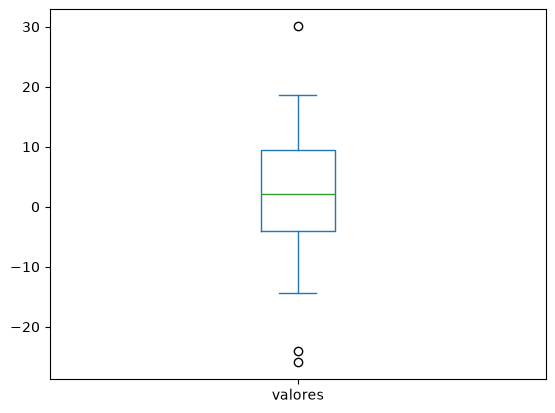

In [88]:
s.plot(kind='box', whis=1.5);


No _background_ o pandas vai utilizar uma libraria para efetuar os gráficos (por defeito o `matplotlib`). Também podemos recorrer diretamente ao `matplolib`, utilizando a função `boxplot`, do módulo `pyplot`.

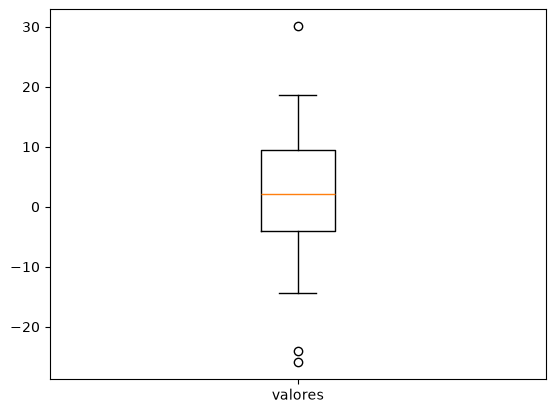

In [89]:
import matplotlib.pyplot as plt

plt.boxplot(s, tick_labels=[s.name], whis=1.5);

Com o parâmetro `kind='hist'` podemos apresentar um histograma, útil para ver a distribuição dos dados. O `matplotlib`, por defeito, faz uma distribuição dos dados por 10 intervalos, mas pode-se utilizar o parâmetro `bins` para indicar o número de intervalos pretendidos:

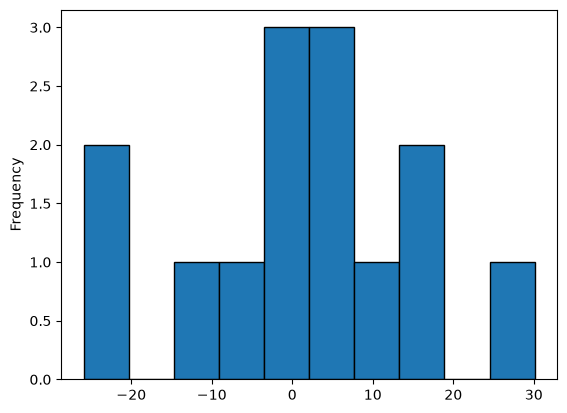

In [90]:
s.plot(kind='hist', bins=10, edgecolor='black');

Num histograms pode-se ter uma indicação visual da existência de _outliers_ através de intervalos isolados. Nem sempre isso quer dizer que existem _outliers_, mas pode ser uma primeira indicação sobre a sua existência.
No caso acima, pode-se ver que existem dois intervalos isolados, quer acima quer abaixo, coerentes com a existência de _outliers_ identificados previamente.

Já verificamos a existência de _outliers_, mas quais são? Vamos então utilizar a regra de Tukey, e calcular os limites "aceitáveis" dos dados, para saber quais os valores que não estão nesse intervalo.

Vamos começar por determinar o valor de `Q1` e `Q3`. Para calcular esses quartis podemos utilizar o método `quantile`, passando o valor de percentagem que se pretende (25% e 75%, respetivamente para Q1 e Q3), e depois podemos calcular o IQR, e os respetivos limites superior e inferior. Vamos calcular esses valores:

In [91]:
Q1 = s.quantile(0.25)
Q3 = s.quantile(0.75)
IQR = Q3 - Q1
print(f'{Q1 = }\n{Q3 = }\n{IQR = }')

Q1 = np.float64(-3.9750000000000005)
Q3 = np.float64(9.4)
IQR = np.float64(13.375)


In [92]:
inf = Q1 - 1.5*IQR
sup = Q3 + 1.5*IQR
print(f'{inf = }\n{sup = }')

inf = np.float64(-24.0375)
sup = np.float64(29.4625)


Depois de saber os os limites podemos identificar e/ou filtrar os _outliers_, utilizando os operadores lógicos do pandas (`&`,`|` e `~`, respetivamente para `E`, `OU` e `NÃO`):

In [93]:
outliers_idx = (s<inf) | (s>sup)
outliers_idx

0     False
1     False
2     False
3      True
4     False
5     False
6     False
7     False
8     False
9      True
10    False
11    False
12    False
13     True
Name: valores, dtype: bool

> **NOTA:**
>
> Os operadores lógicos `and`, `or` e `not` são para objetos do Python, e não podem ser _overloaded_. O pandas utiliza os operadores bit a bit do Python (respetivamente `&`,  `|` e `~`) e faz o _overload_ para trabalhar com objectos do pandas.

Identificamos os índices dos _outliers_, vamos saber quantos são e quais são os elementos:

In [94]:
outliers = s[outliers_idx]
print(f'Existem {len(outliers)} outliers nos dados:')
print(outliers)

Existem 3 outliers nos dados:
3    -24.1
9    -25.9
13    30.1
Name: valores, dtype: float64


Podemos ver que existem 3 valores que são considerados _outliers_, mas o que fazer com esses valores depende muito quer da razão da existência dos _outliers_ quer do tamanho do _dataset_.

No caso de _datasets_ pequenos, a remoção de qualquer valor pode ter influência nos dados, mas _outliers_ podem distorcer as estatísticas, pelo que é necessário considerar com atenção caso a caso.

No caso de _datasets_ muito grandes, os _outliers_ terão menos influência nas estatísticas, e a sua remoção terá (normalmente) menos consequências, mas em todo o caso a opção de remover deverá ser devidamente ponderada e nunca deverá ser a primeira e/ou única opção.

Caso se consiga identificar que os _outliers_ foram resultado de erros de medição ou de introdução e caso se consiga corrigir esse valor, o problema está resolvido. Por exemplo, numa listagem com a altura de vários indivíduos (vamos supor que todos os valores serão `1.xx`), se aparecer um valor `10.xx` (claramente um _outlier_), uma explicação razoável é que foi inserido um `0` erradamente, e podemos corrigir esse valor.

Caso o _outlier_ não se consiga corrigir, podemos substituir ou remover os _outliers_ (mais uma vez com cuidado, pois podemos perder informação). No caso da substituição, podemos utilizar a mediana pois isso irá preservar a distribuição dos dados, ou, para grandes _datasets_, podemos truncar os dados, ou seja, substituir todos os valores abaixo/acima de um determinado limite por valores mínimos/máximos aceitáveis.

Substituir pela mediana ou fazer a truncagem depende, em grande parte, do contexto na análise e do comportamento dos dados.

Substituir pela mediana, como foi dito, não distorce a distribuição dos dados pois é mediana é a medida de centraliade, inserir "mais" valores centrais não vai provocar disturbios nos dados, mas tem a desvantagem de se poder perder um pouco a variabilidade dos dados (valores extremos são substituídos pela mediana), o que pode fazer com que ocorra um sub-representação dos valores extremos, principalmente em grandes _datasets_.

Por seu lado, efetuar a truncagem pode manter a variabilidade dos dados, pois os _outliers_ são substituídos por valores máximos/mínimos aceitáveis, dentro de um intervalo pré-definido (normalmente baseado em percentis, como 5% e 95%), mantém a variabilidade dos dados. Por outro lado, a escolha dos valores a substituir pode ser subjetiva, os percentis 5% e 95% podem não ser adequados a todos os dados, e uma escolha errada pode induzir um viés nos dados.

No caso do presente exemplo, o _dataset_ é extremamente pequeno. Temos 14 elementos, dos quais 3 são _outliers_, caso se removessem os _outliers_ perdíamos um pouco mais de 20% dos nossos dados, pelo que iremos substitui-los pela mediana:

In [95]:
s[outliers_idx] = s.median()
s

0      2.2
1     17.8
2    -14.4
3      2.1
4      0.0
5     -1.2
6      3.9
7     10.9
8      2.0
9      2.1
10    -4.9
11    18.7
12     4.9
13     2.1
Name: valores, dtype: float64

### _One-hot Encoding_ (Codificação _one-hot_ de variáveis categóricas)

Se num `DataFrame` existe uma coluna com `k` valores diferentes, pode ser útil substituir essa coluna por `k` colunas diferentes com `True` ou `False`. O pandas tem a função `get_dummies` que faz exatamente isso:

In [96]:
dict1 = {
    "chave": ["b", "b", "a", "c", "a", "b"],
    "valor": [1.2, 1.1, 4.2, 2.3, 5.1, 3.1]
}

df = pd.DataFrame(dict1)
df

,chave,valor
0,b,1.2
1,b,1.1
2,a,4.2
3,c,2.3
4,a,5.1
5,b,3.1


In [97]:
pd.get_dummies(df['chave'], dtype='Int64')

,a,b,c
0,0,1,0
1,0,1,0
2,1,0,0
3,0,0,1
4,1,0,0
5,0,1,0


Acima pode-se ver que foi passado o `dtype='Int64'` para os valores devolvidos sejam `1/0` e não `True/False`. Como se pode ver, foi devolvido um `DataFrame` onde em cada linha só existe um único `1`, que corresponde ao respetivo valor.

Em alguns casos pode ser necessário adicionar um prefixo ao nome da coluna, de forma a combinar essa `DataFrame` com outro:

In [98]:
dummies = pd.get_dummies(df['chave'], dtype='Int64', prefix='chave')
dummies

,chave_a,chave_b,chave_c
0,0,1,0
1,0,1,0
2,1,0,0
3,0,0,1
4,1,0,0
5,0,1,0


In [99]:
all = pd.concat([df['valor'], dummies], axis=1)
all

,valor,chave_a,chave_b,chave_c
0,1.2,0,1,0
1,1.1,0,1,0
2,4.2,1,0,0
3,2.3,0,0,1
4,5.1,1,0,0
5,3.1,0,1,0


Considere agora o ficheiro `exemplos\movies.csv`, onde está uma lista de filmes, com uma coluna onde o género do filme está concatenado com um `|`:

In [100]:
movies = pd.read_csv(r'exemplos\movies.csv', names=['movie', 'genre'])
print(movies.head(10))

                                 movie                         genre
1                     Toy Story (1995)   Animation|Children's|Comedy
2                       Jumanji (1995)  Adventure|Children's|Fantasy
3              Grumpier Old Men (1995)                Comedy|Romance
4             Waiting to Exhale (1995)                  Comedy|Drama
5   Father of the Bride Part II (1995)                        Comedy
6                          Heat (1995)         Action|Crime|Thriller
7                       Sabrina (1995)                Comedy|Romance
8                  Tom and Huck (1995)          Adventure|Children's
9                  Sudden Death (1995)                        Action
10                    GoldenEye (1995)     Action|Adventure|Thriller


A função `get_dummies` aqui não irá funcionar, pois a coluna `genre` não tem valores diferentes em si, mas cada elemento é uma lista. Estes casos são frequentes, e o pandas tem o método `str.get_dummies`, que permite fazer o que se pretende:

In [101]:
genres = movies['genre'].str.get_dummies('|')
genres.iloc[:10,:5]

,Action,Adventure,Animation,Children's,Comedy
1,0,0,1,1,1
2,0,1,0,1,0
3,0,0,0,0,1
4,0,0,0,0,1
5,0,0,0,0,1
6,1,0,0,0,0
7,0,0,0,0,1
8,0,1,0,1,0
9,1,0,0,0,0
10,1,1,0,0,0


Tal como anteriormente, podemos combinar o `DataFrame` gerado com outro `DataFrame`, e pode-se também utilizar o método `add_prefix` para adicionar um prefixo a todas as colunas do `DataFrame`:

In [102]:
movies = pd.concat([movies['movie'], genres.add_prefix('genre_')], axis=1)
movies.head()

,movie,genre_Action,genre_Adventure,genre_Animation,genre_Children's,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,genre_Fantasy,genre_Film-Noir,genre_Horror,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War
1,Toy Story (1995),0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
2,Jumanji (1995),0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0
3,Grumpier Old Men (1995),0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
4,Waiting to Exhale (1995),0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
5,Father of the Bride Part II (1995),0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


Com os dados neste forma, é fácil saber quantos filmes de um determinado género existem:

In [103]:
movies['genre_Action'].sum()

np.int64(28)

Ou quantos filmes de cada género existem nos nossos dados:

In [104]:
movies.sum().iloc[1:]

genre_Action         28
genre_Adventure      20
genre_Animation       3
genre_Children's     16
genre_Comedy         57
genre_Crime          14
genre_Documentary    11
genre_Drama          93
genre_Fantasy         4
genre_Film-Noir       1
genre_Horror          6
genre_Musical         4
genre_Mystery         5
genre_Romance        33
genre_Sci-Fi         11
genre_Thriller       33
genre_War             6
dtype: object

### Manipulação de _strings_

O Python já tem muitas funções que permite trabalhar com _strings_, como sejam separar _strings_ utilizando um determinado caractere, limpar espaços em branco no inicio/fim da string, juntar elementos de uma lista numa única string, etc.

A função `split` permite separar uma _string_ numa lista de _strings_, utilizando o caractere indicado como separador:

In [105]:
val = "   a   ,    b,  guido   "

val.split(",")

['   a   ', '    b', '  guido   ']

Frequentemente remove-se os espaços em branco no mesmo passo:

In [106]:
pieces = [x.strip() for x in val.split(",")]
pieces

['a', 'b', 'guido']

Caso se queira, pode-se unir a lista de _strings_ de novo numa única string, utilizando o método `join`:

In [107]:
"|".join(pieces)

'a|b|guido'

Abaixo uma lista **não exaustiva** de alguns métodos para manipular _strings_, disponíveis no Python:

| Método | Descrição |
|--------|-----------|
| `count` | Devolve o número de ocorrências de uma _substring_ na _string_ |
| `endswith` | Devolve `True` caso a _string_ termine no sufixo indicado |
| `startswith` | Devolve `True` caso a _string_ comece com  o prefixo indicado |
| `join` | Us uma _string_ como delimitador para concatenar uma lista de _strings_
| `index` | Devolve o índice da primeira ocorrência da _substring_ na _string_. Caso não encontre, devolve `ValueError`.
| `find` | Devolve o índice da primeira ocorrência da _substring_ na _string_. Caso não encontre, devolve `-1.
| `rfind` | Devolve o índice da última ocorrência da _substring_ na _string_. Caso não encontre, devolve `-1.
| `replace` | Substitui as ocorrências de uma _string_ por outra.
| `strip`, `rstrip`, `lstrip` | Remove espaços em branco, incluindo `\n`, em ambos os lados, apenas no fim e apenas no inicio, respetivamente.
| `split` | Separa a _string_ numa lista de _substring_ utilizando o delimitador indicado
| `lower` | Converte em minúsculas
| `upper` | Converte em maiúsculas

#### Expressões regulares

As expressões regulares são uma forma de procurar padrões num texto. Uma expressão regular, normalmente denominada _regex_ é uma _string_ formada de acordo com as regras das expressões regulares.

No Python existe o módulo `re` que implementa as funções que permitem utilizar expressões regulares em _strings_.

Considere a seguinte "frase":

In [108]:
text = 'foo    bar\t olá  \nmundo!'

Se quisermos separar a frase pelos espaços em branco e utilizarmos utilizar o método `split`:

In [109]:
text.split(' ')

['foo', '', '', '', 'bar\t', 'olá', '', '\nmundo!']

Podemos ver que não funciona como se pretendia.

Pelo contrário, se utilizarmo o método `split` do módulo `re`, utilizando uma _regex_ apropriada (que já vimos anteriormente):

In [110]:
import re

re.split(r'\s+', text)

['foo', 'bar', 'olá', 'mundo!']

Caso se queira ver todos as _subtrings_ que verificam o padrão, isso pode ser feito com a função `findall`:

In [111]:
re.findall(r'\s+', text)

['    ', '\t ', '  \n']

Mas estar constantemente a escrever a _regex_ (e algumas podem ser bastante complexas), para além de trabalhoso, também não é muito eficiente, pois a _regex_ está constantemente a ser compilada. Utilizando a função `compile` pode-se fazer isso uma vez, e temos um objecto _regex_ reutilizável:

In [112]:
regex = re.compile(r'\s+')

regex.findall(text)

['    ', '\t ', '  \n']

Para além da função `findall`, existe também a função `search`, que devolve apenas a primeira correspondência, e a `match` que procura correspondências apenas no inicio da _string_

In [113]:
s = regex.search(text)
s

<re.Match object; span=(3, 7), match='    '>

In [114]:
m = regex.match(text)
print(m)

None


O match acima não devolve nada pois não existe nenhuma espaço em branco (a _regex_ utilizada) no **inicio** da _string_.

Outro exemplo: Suponha que tem uma mensagem, e que queria procurar todos os endereços de email na mensagem.

In [115]:
msg = """Durante a reunião da equipa, Maria (maria.silva@empresa.com)
apresentou o novo projeto de marketing. João (joao123@mail.org) sugeriu
algumas alterações, enquanto Ana (ana.pereira@tech-corp.net) ficou
responsável pela implementação técnica. Para dúvidas adicionais, a
equipe foi orientada a contatar o suporte em helpdesk@suporte.com.pt.
"""

A _regex_ abaixo é uma forma de identificar endereços de email (é uma forma simplificada, não permite identificar todas as variações atualmente permitidas num endereço de email):

In [116]:
padrao_email = r'[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,4}'

regex = re.compile(padrao_email, flags=re.IGNORECASE)

In [117]:
regex.findall(msg)

['maria.silva@empresa.com',
 'joao123@mail.org',
 'ana.pereira@tech-corp.net',
 'helpdesk@suporte.com.pt']

In [118]:
email = regex.search(msg)

print(email[0])
print(f'indice inicial: {email.start()}')
print(f'indice final: {email.end()}')
print(f'{msg[email.start():email.end()] = }')

maria.silva@empresa.com
indice inicial: 36
indice final: 59
msg[email.start():email.end()] = 'maria.silva@empresa.com'


A função `sub` permite substituir as ocorrencias da _regex_ por outra _string_:

In [119]:
filtrada = regex.sub('EMAIL_REMOVIDO', msg)
print(filtrada)

Durante a reunião da equipa, Maria (EMAIL_REMOVIDO)
apresentou o novo projeto de marketing. João (EMAIL_REMOVIDO) sugeriu
algumas alterações, enquanto Ana (EMAIL_REMOVIDO) ficou
responsável pela implementação técnica. Para dúvidas adicionais, a
equipe foi orientada a contatar o suporte em EMAIL_REMOVIDO.



As _regex_ também permitem segmentar a expressão regular em _grupos_, e trabalhar com cada um de forma individual. Para isso deve-se definir os grupos na _regex_ metendo parênteses à volta dos grupos que se prentende.

Suponha que pretende obter o nome do email (a parte antes do `@`), o domínio da empresa (a parte entre o `@` e o último `. `) e o domínio principal (o que vem depois do último `.`):

In [120]:
padrao_email = r'([A-Z0-9._%+-]+)@([A-Z0-9.-]+)\.([A-Z]{2,4})'

regex = re.compile(padrao_email, flags=re.IGNORECASE)

In [121]:
m = regex.match("pmguerre@ualg.pt")
m.groups()

('pmguerre', 'ualg', 'pt')

In [122]:
m = regex.findall(msg)
m

[('maria.silva', 'empresa', 'com'),
 ('joao123', 'mail', 'org'),
 ('ana.pereira', 'tech-corp', 'net'),
 ('helpdesk', 'suporte.com', 'pt')]

Utilizar "grupos" permite ter acesso a cada componente dos grupos e tratar apenas um (ou vários) grupos, utilizando simbolos especiais: `\1` para o primeiro grupo, `\2` para o segundo grupo, etc.

Por exemplo, na mensagem inicial, queremos remover apenas o domínio da empresa, ficando o nome do email e o domínio de topo:

In [123]:
filtrada = regex.sub(r'\1@...\3', msg)
print(filtrada)

Durante a reunião da equipa, Maria (maria.silva@...com)
apresentou o novo projeto de marketing. João (joao123@...org) sugeriu
algumas alterações, enquanto Ana (ana.pereira@...net) ficou
responsável pela implementação técnica. Para dúvidas adicionais, a
equipe foi orientada a contatar o suporte em helpdesk@...pt.



#### Strings no pandas

As funções de _strings_ no Python podem ser utilizadas nas `Series` e `DataFrame` do pandas através dos métodos `apply` e `map`, mas não em formato vetorial nativo, o que vai provocar um menor eficiência no processamento, tanto maior quanto maior for a informação a tratar.

Além disso, caso existam valores vazios, pode ocorrer um erro, como se pode ver abaixo:

In [124]:
func = [
    {'nome': 'Maria Silva', 'email': 'maria.silva@empresa.com'},
    {'nome': 'João', 'email': 'joao123@mail.org'},
    {'nome': 'Ana Pereira', 'email': 'ana.pereira@tech-corp.net'},
    {'nome': pd.NA, 'email': 'helpdesk@suporte.com.pt'},
    {'nome': 'Pedro', 'email': pd.NA}
]

In [125]:
df = pd.DataFrame(func, dtype='string')
df

,nome,email
0,Maria Silva,maria.silva@empresa.com
1,João,joao123@mail.org
2,Ana Pereira,ana.pereira@tech-corp.net
3,<NA>,helpdesk@suporte.com.pt
4,Pedro,<NA>


Se passarmos tudo para maiúsculas utilizando o método `map` e recurrendo aos métodos das _strings_ do Python, teríamos uma exceção, devido à existência de valores vazios, que as _strings_ do Python não conhecem:

In [126]:
try:
    df.map(lambda x: x.upper())
except AttributeError as e:
    print(f'ERROR: {e}')

ERROR: 'NAType' object has no attribute 'upper'


Mas apenas para as três primeiras linhas, isso pode ser feito sem problemas pois, no exemplo, não existem valores vazios nessas linhas:

In [127]:
df.loc[:2].map(lambda x: x.upper())

,nome,email
0,MARIA SILVA,MARIA.SILVA@EMPRESA.COM
1,JOÃO,JOAO123@MAIL.ORG
2,ANA PEREIRA,ANA.PEREIRA@TECH-CORP.NET


Para evitar esses problemas, e para permitir trabalhar com _strings_ em formato vetorial, existe no pandas um atributo especial das `Series` que é o `str`:

In [128]:
df['nome'].str.upper()

0    MARIA SILVA
1           JOÃO
2    ANA PEREIRA
3           <NA>
4          PEDRO
Name: nome, dtype: string

In [129]:
df['email'].str.contains('com')

0     True
1    False
2    False
3     True
4     <NA>
Name: email, dtype: boolean

> **NOTA:**
>
> O atributo `str` só existe na `Series`, não existe no `DataFrame`, isto porque cada coluna pode ter um tipo de dados diferente, por isso este processamento deve ser aplicado à coluna (`Series`).

Por exemplo, pode-se utilizar o método `findall` diretamente no `str`, e utilizar as _flags_ do módulo `re`:

In [130]:
padrao_email = r'([A-Z0-9._%+-]+)@([A-Z0-9.-]+)\.([A-Z]{2,4})'

match = df['email'].str.findall(padrao_email, flags=re.IGNORECASE)
match

0      [(maria.silva, empresa, com)]
1             [(joao123, mail, org)]
2    [(ana.pereira, tech-corp, net)]
3      [(helpdesk, suporte.com, pt)]
4                               <NA>
Name: email, dtype: object

Para ter aceder aos elementos de forma vetorial, pode-se utilizar o método `str.get` utilizar o índice diretamente no `str`:

In [131]:
match.str[0]

0      (maria.silva, empresa, com)
1             (joao123, mail, org)
2    (ana.pereira, tech-corp, net)
3      (helpdesk, suporte.com, pt)
4                             <NA>
Name: email, dtype: object

In [132]:
match.str[0].str[2]

0     com
1     org
2     net
3      pt
4    <NA>
Name: email, dtype: object

In [133]:
match.str[0].str.get(2)

0     com
1     org
2     net
3      pt
4    <NA>
Name: email, dtype: object

Pode-se inclusive, utilizar _slices_:

In [134]:
match.str[0].str[0].str[:3]

0     mar
1     joa
2     ana
3     hel
4    <NA>
Name: email, dtype: object

Por vezes também pode ser útil construir um `DataFrame` com base nos grupos identificados. Isso pode ser feito com o método `str.extract`:

In [135]:
df['email'].str.extract(padrao_email, flags=re.IGNORECASE)

,0,1,2
0,maria.silva,empresa,com
1,joao123,mail,org
2,ana.pereira,tech-corp,net
3,helpdesk,suporte.com,pt
4,<NA>,<NA>,<NA>


Alguns métodos que permite trabalhar com _strings_ a partir do atributo `str` são:



| Método | Descrição |
| ------ | --------- |
| `cat` | Cancatena _strings_ elemento a elemento
| `contains` | Devolve um _array_ booleano com a verificação se cada elemento contêm o padrão
| `count` | Conta as ocorrências do padrão
| `extract` | Extrai os elementos que verificarem a expressão regular para um `DataFrame`
| `endswith` | Equivalente a x.endswith(padrão) para cada elemento
| `startswith` | Equivalente a x.startswith(padrão) para cada elemento
| `findall` | Obtém a lista de todas as ocorrências do padrão/_regex_ para cada elemento
| `get` | Devolve o i-ésimo elemento
| `isalnum`, `isalpha`, `isdecimal`, `isdigit`, <br>`islower`, `isnumeric`, `isupper` | Equivalentes às respetivas funções das _string_ do Python
| `join` | Junta as _strings_ existentes em cada elemento, utilizando a _string_ fornecida
| `len` | Devolve o comprimento de cada _string_
| `lower, upper` | Converte de/para maiúsculas/minúsculas
| `match` | Utiliza o `re.match`com a _regex_ fornecida em cada elemento
| `replace` | Substitui as ocorrências do padrão/_regex_ com outra _string_
| `slice` | Fatia (_slice_) cada _string_
| `split` | Separa as _string_ com base no delimitador ou _regex_ fornecido
| `rstrip`, `lstrip`, `strip` | Remove da _string_ os espaços em branco ou caractere fornecidos, respetivamente direita, à esquerda ou em ambos os lados

### Categorias

Previamente já vimos um pouco das categorias, vamos ver agora como de pode utilizar as categorias como forma de aumentar a performance e diminuir o utilização de memória.

É frequente existir nos _datasets_ uma coluna com muitos valores repetidos, e onde o conjunto de valores distintos seja pequeno, por exemplo, uma coluna com o sexo dos individuos, onde os conjunto de valores distintos é pequena (`'M'` ou `'F'`), mas, dependendo do tamanho do _dataset_, podem existir centenas ou milhares de repetições desses dois valores.

Considere o seguinte exemplo:

In [136]:
import numpy as np
N = 10
data = {'fruta': [np.random.choice(['ananás', 'laranja', 'maçã']) for _ in range(N)],
        'stock': [np.random.randint(3,15) for _ in range(N)],
        'peso': [np.random.random()*10 for _ in range(N)]
       }

In [137]:
tipos = {'fruta': 'string', 'stock': 'Int64', 'peso':'float64'}
df1 = pd.DataFrame(data).astype(tipos)
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   fruta   10 non-null     string 
 1   stock   10 non-null     Int64  
 2   peso    10 non-null     float64
dtypes: Int64(1), float64(1), string(1)
memory usage: 382.0 bytes


In [138]:
df1

,fruta,stock,peso
0,laranja,5,5.803854
1,maçã,9,4.734222
2,laranja,13,4.849826
3,ananás,8,5.079666
4,ananás,11,5.235007
5,laranja,9,7.916619
6,ananás,13,5.146784
7,laranja,3,1.191987
8,maçã,3,1.617830
9,ananás,12,7.934210


Pode-se ver que o nome da fruta está a ser repetido várias vezes:

In [139]:
df1['fruta'].unique()

<StringArray>
['laranja', 'maçã', 'ananás']
Length: 3, dtype: string

In [140]:
df1['fruta'].value_counts()

fruta
laranja    4
ananás     4
maçã       2
Name: count, dtype: Int64

Pode-se converter a coluna `fruta` para o tipo categoria utilizando o método `astype`:

In [141]:
df2 = df1.copy()
df2['fruta'] = df2['fruta'].astype('category')
df2['fruta']

0    laranja
1       maçã
2    laranja
3     ananás
4     ananás
5    laranja
6     ananás
7    laranja
8       maçã
9     ananás
Name: fruta, dtype: category
Categories (3, string): ['ananás', 'laranja', 'maçã']

Pode-se aceder às propriedades das categorias utilizando as propriedades dentro do atributo `.cat`, como sejam `categories` e `codes`: O primeiro devolve quais os "nomes" guardados (categorias), o segundo faz uma correspondência, utilizando valores inteiros (códigos), da categoria correspondente a cada elemento da `Series`:

In [142]:
frutas = df2['fruta'].cat.categories
frutas

Index(['ananás', 'laranja', 'maçã'], dtype='string')

In [143]:
dict(enumerate(frutas))

{0: np.str_('ananás'), 1: np.str_('laranja'), 2: np.str_('maçã')}

In [144]:
df2['fruta'].cat.codes

0    1
1    2
2    1
3    0
4    0
5    1
6    0
7    1
8    2
9    0
dtype: int8

Pode-se ver acima que os dois primeiros elementos da coluna "fruta" são da categoria `2`, que corresponde à categoria `maçã`, de acordo com o dicionário das frutas, apresentado acima, o que corresponde aos valores do `DataFrame` criado inicialmente.

Pode-se criar categorias diretamente com o método `Categorical` a partir de sequências do Python:

In [145]:
c = pd.Categorical([1, 2, 1, 2, 0, 0, 1])
c

[1, 2, 1, 2, 0, 0, 1]
Categories (3, int64): [0, 1, 2]

Mas atenção que neste caso não obtemos uma `Series`, mas sim um variável do tipo categoria (`Categorical`):

In [146]:
type(c)

pandas.Categorical

Esta variável pode ser depois utilizada para criar uma `Series`:

In [147]:
pd.Series(c)

0    1
1    2
2    1
3    2
4    0
5    0
6    1
dtype: category
Categories (3, int64): [0, 1, 2]

Ou um `DataFrame`:

In [148]:
pd.DataFrame(c)

,0
0,1
1,2
2,1
3,2
4,0
5,0
6,1


Por vezes obtemos os códigos e as categorias de fontes independentes. Por exemplo, podemos ter uma lista com as "faltas" dos alunos, unicamente com valores 0, 1, 2, e depois existir na documentação uma legenda a indicar que o valor 0 significa que faltou, 1 significa que justificou a falta e 2 que esteve presente.

In [149]:
categorias = ['faltou', 'justificado', 'presente']
lista_de_faltas = [0, 1, 1, 2, 2, 2, 0, 0, 2, 2, 2]

Pode-se criar uma categoria a partir desta informação utilizando o método `from_codes`. Note-se que as categorias, por defeito não são ordenadas, mas pode-se utilizar o parâmetro `ordered=True` nos construtores das categorias, para indicar uma categoria ordenada:

In [150]:
faltas = pd.Series(
    pd.Categorical.from_codes(lista_de_faltas, categorias, ordered=True)
)
faltas

0          faltou
1     justificado
2     justificado
3        presente
4        presente
5        presente
6          faltou
7          faltou
8        presente
9        presente
10       presente
dtype: category
Categories (3, str): ['faltou' < 'justificado' < 'presente']

Relembro que as funções `cut` e `qcut`, vistas acima, devolvem uma variável do tipo categoria, e essas sim, por defeito ordenadas:

In [151]:
# Vamos criar uma lista com 1000 valores aleatórios no intervalo [-50; 50]
nums = [int(np.random.random()*100-50) for _ in range(1000)]

cat = pd.qcut(nums, 4)
cat

[(-22.0, 3.0], (-22.0, 3.0], (-49.001, -22.0], (3.0, 26.0], (26.0, 49.0], ..., (-22.0, 3.0], (-49.001, -22.0], (26.0, 49.0], (-49.001, -22.0], (-49.001, -22.0]]
Length: 1000
Categories (4, interval[float64, right]): [(-49.001, -22.0] < (-22.0, 3.0] < (3.0, 26.0] < (26.0, 49.0]]

In [152]:
cat.categories

IntervalIndex([(-49.001, -22.0], (-22.0, 3.0], (3.0, 26.0], (26.0, 49.0]], dtype='interval[float64, right]')

In [153]:
cat.value_counts()

(-49.001, -22.0]    254
(-22.0, 3.0]        249
(3.0, 26.0]         257
(26.0, 49.0]        240
Name: count, dtype: int64

#### Performance das categorias

Relativamente à performance, e só por curiosidade, relativamente à memória utilizada, pode-se ver utilizando o método `memory_usage` que o `DataFrame` que está a utilizar as categorias (`df2`) está a ocupar menos memória na coluna "fruta", do que o `DataFrame` que está a utilizar _strings_ (`df1`):

In [154]:
df1.memory_usage(deep=True)

Index    132
fruta    836
stock     90
peso      80
dtype: int64

In [155]:
df2.memory_usage(deep=True)

Index    132
fruta    261
stock     90
peso      80
dtype: int64

Da mesma forma pode-se ver uma estimativa do tempo gasto num calculo simples, utilizando o tipo `string` (`df1`), e utilizando o tipo `category` (`df2`), mesmo com um número muito reduzido de elementos:

In [156]:
%timeit df1['fruta'].value_counts()

218 μs ± 27.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [157]:
%timeit df2['fruta'].value_counts()

105 μs ± 4.68 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


Claro que que a memória quer o tempo não são muito diferentes, mas o exemplo tem 10 elementos. Quando mais elementos mais diferente serão os resultados.

#### Métodos próprios das categorias

Tal como existem métodos próprios para as `Series.str`, também existem métodos próprios para as categorias, acessíveis a partir do atributo especial `.cat`.

Acima, já vimos os atributos `categories`, e `codes`:

In [158]:
s1 = pd.Series(list('abcd')*2, dtype='category')
s1

0    a
1    b
2    c
3    d
4    a
5    b
6    c
7    d
dtype: category
Categories (4, str): ['a', 'b', 'c', 'd']

In [159]:
s1.cat.categories

Index(['a', 'b', 'c', 'd'], dtype='str')

In [160]:
s1.cat.codes

0    0
1    1
2    2
3    3
4    0
5    1
6    2
7    3
dtype: int8

Suponha que afinal se verificou que existe mais uma categoria que não estava nos valores iniciais. Pode-se alterar as categorias através do método `set_categories`:

In [161]:
s2 = s1.cat.set_categories(list('abcde'))
s2

0    a
1    b
2    c
3    d
4    a
5    b
6    c
7    d
dtype: category
Categories (5, str): ['a', 'b', 'c', 'd', 'e']

Apesar de parecer que os dados estão inalterados, as novas categorias serão refletidas nas operações, isso pode ser visto, por exemplo, no método `value_counts`:

In [162]:
s1.value_counts()

a    2
b    2
c    2
d    2
Name: count, dtype: int64

In [163]:
s2.value_counts()

a    2
b    2
c    2
d    2
e    0
Name: count, dtype: int64

Em grandes _datasets_ a utilização de categorias pode ser utilizada para poupar memória e/ou obter uma melhor performance na análise posterior.

Dependendo do tipo de limpeza e tratamento dos dados efetuado, pode acontecer que muitos valores das categorias desapareçam dos dados. Podemos utilizar o método `remove_unused_categories` para remover as categorias não presentes nos dados.

Vamos exemplificar, "limpando" os códigos das categorias, e ficando apenas com as categorias `a` e `b` do exemplo acima:

In [164]:
s3 = s1[s1.isin(['a', 'b'])]
s3

0    a
1    b
4    a
5    b
dtype: category
Categories (4, str): ['a', 'b', 'c', 'd']

In [165]:
s3 = s3.cat.remove_unused_categories()
s3

0    a
1    b
4    a
5    b
dtype: category
Categories (2, str): ['a', 'b']

Também existe o método `remove_categories`, que remove as categorias indicadas e, consequentemente, os respetivos códigos passam a não existir (`NaN`):

In [166]:
s2.cat.remove_categories(['a', 'b', 'c'])

0    NaN
1    NaN
2    NaN
3      d
4    NaN
5    NaN
6    NaN
7      d
dtype: category
Categories (2, str): ['d', 'e']

Abaixo estão alguns métodos que temos acesso a partir do atributo `.cat`:

| Método | Descrição |
| ------ | --------- |
| `add_categories` | Acrescenta novas categorias no fim das categorias existentes
| `as_ordered` | Torna as categorias ordenadas
| `as_unordered` | Remove a ordem das as categorias
| `remove_categories` | Remove categorias, e atribui `NaN` aos valores removidos
| `remove_unused_categories` | Remove todas as categorias que não aparecem nos dados
| `rename_categories` | Substitue as categorias com uma nova lista de categorias. O número de categorias não pode ser alterado
| `reorder_categories` | Similar a `rename_categories`, mas com ordem nas categorias
| `set_categories` | Substitue as categorias com uma nova lista de categorias. Pode-se alterar o número de categorias